# Data Science Laboratory: Unsupervised Learning
Pablo Méndez

MsC. Computation Biomedical Engineering 2026-27

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat

# 1. Principal Component Analysis

In [48]:
features = ["age","bp","sg","al","su","rbc","pc","pcc","ba","bgr","bu","sc","sod","pot","hemo","pcv","wc","rc","htn","dm","cad","appet","pe","ane","class"]

In [49]:
df_kidney = pd.read_csv("../data/chronic_kidney_disease_ad.csv", names=features)

df_kidney.shape

(400, 25)

In [50]:
df_kidney.head()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,NaN,0.0,0.0,0.0,121.0,...,44.0,7800.0,5.2,1.0,1.0,0.0,0.0,0.0,0.0,1
1,7.0,50.0,1.020,4.0,0.0,NaN,0.0,0.0,0.0,NaN,...,38.0,6000.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,1
2,62.0,80.0,1.010,2.0,3.0,0.0,0.0,0.0,0.0,423.0,...,31.0,7500.0,NaN,0.0,1.0,0.0,1.0,0.0,1.0,1
3,48.0,70.0,1.005,4.0,0.0,0.0,1.0,1.0,0.0,117.0,...,32.0,6700.0,3.9,1.0,0.0,0.0,1.0,1.0,1.0,1
4,51.0,80.0,1.010,2.0,0.0,0.0,0.0,0.0,0.0,106.0,...,35.0,7300.0,4.6,0.0,0.0,0.0,0.0,0.0,0.0,1


In [51]:
df_kidney.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     391 non-null    float64
 1   bp      388 non-null    float64
 2   sg      353 non-null    float64
 3   al      354 non-null    float64
 4   su      351 non-null    float64
 5   rbc     248 non-null    float64
 6   pc      335 non-null    float64
 7   pcc     396 non-null    float64
 8   ba      396 non-null    float64
 9   bgr     356 non-null    float64
 10  bu      381 non-null    float64
 11  sc      383 non-null    float64
 12  sod     313 non-null    float64
 13  pot     312 non-null    float64
 14  hemo    348 non-null    float64
 15  pcv     329 non-null    float64
 16  wc      294 non-null    float64
 17  rc      269 non-null    float64
 18  htn     398 non-null    float64
 19  dm      398 non-null    float64
 20  cad     398 non-null    float64
 21  appet   399 non-null    float64
 22  pe

In [52]:
df_kidney.nunique()

age       76
bp        10
sg         5
al         6
su         6
rbc        2
pc         2
pcc        2
ba         2
bgr      146
bu       118
sc        84
sod       34
pot       40
hemo     115
pcv       42
wc        89
rc        45
htn        2
dm         2
cad        2
appet      2
pe         2
ane        2
class      2
dtype: int64

As we see, although all features seemed numerical, lots of them are categorical (as they only have two possible values).

## 1.1. Application to clinical data

### 1.1.1. Pre-processing of the data

**Why is this data a good candidate for dimensionality reduction?**

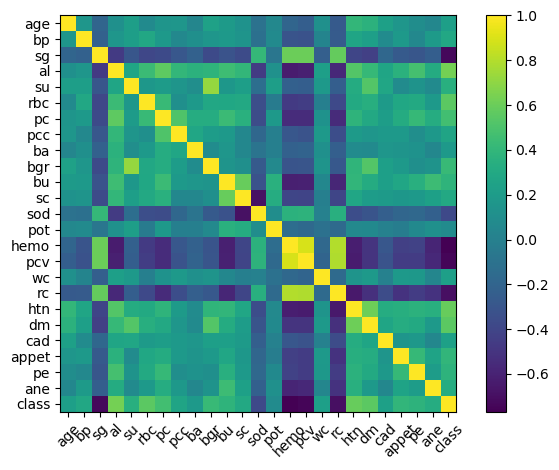

In [53]:
# View graphically correlations between features
corr = df_kidney.corr()

plt.imshow(corr)
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.tight_layout()
plt.show()

This dataset is a good candidate for dimensionality reduction because its 24 features make visualization difficult. Moreover, the correlation matrix shows both positive and negative correlations between some features, suggesting we might have redundant information in the dataset.

**One general approach to deal with missing data is to replace missing values by the attribute mean. Justify whether this approach is convenient for the Chronic_Kidney_Disease dataset.**

In [54]:
means = df_kidney.mean()
df_kidney = df_kidney.fillna(means)

Mean imputation is a simple baseline that preserves all 400 patients, but it may not be ideal for this dataset. Replacing missing values by the mean reduces variability across patients and may distort correlations. Furthermore, some features are binary categorical variables (0 or 1), so in those cases mean imputation may introduce fractional values that do not correspond to a valid category.

**Divide the dataset into a feature set and a label vector (corresponding to the last column). Note that although you have the labels to know for each case whether it is normal or pathological, these labels are only used in this exercise for visualization purposes.**

In [55]:
X = df_kidney.drop(columns="class")
y = df_kidney["class"]

**Use scatter plots to visualize relationships between (some of the numerical) features (e.g. “blood urea” vs “serum creatinine”). Color the data points according to class label and see whether they are naturally clustered according to diagnosis.**

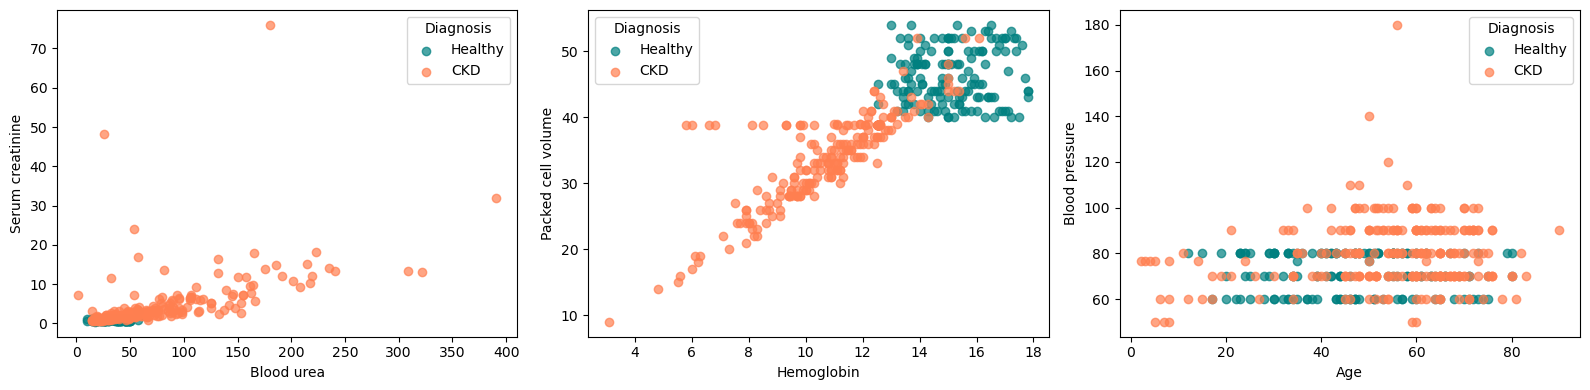

In [56]:
pairs = [("bu", "sc"), ("hemo", "pcv"), ("age", "bp")]
groups = [(0, "Healthy", "teal"), (1, "CKD", "coral")]

names = {
    "bu": "Blood urea",
    "sc": "Serum creatinine",
    "hemo": "Hemoglobin",
    "pcv": "Packed cell volume",
    "age": "Age",
    "bp": "Blood pressure",
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (a, b) in zip(axes, pairs):
    for value, label, color in groups:
        mask = y == value
        ax.scatter(X.loc[mask, a], X.loc[mask, b], color=color, label=label, alpha=0.7)

    ax.set_xlabel(names[a])
    ax.set_ylabel(names[b])
    ax.legend(title="Diagnosis")

plt.tight_layout()
plt.show()

In this subplot we can see 3 two-features scatter plots. In the first one, healthy patients concentrate at lower blood urea and serum creatinine, and although some CKD patients also concentrates in the same area, they are more spread out and often have higher values. In the second, hemoglobin and packed cell volume show a clearer separation, with CKD patients generally having lower values than healthy patients. In the third one, age and blood pressure show considerable overlap between both groups, with no visible cluster separation.

## 1.2. Implementing PCA

**Standardize the variables to have zero mean and unit variance. Why the latter is important?**

In [57]:
means = X.mean(axis=0)
std = X.std(axis=0)

In [58]:
X_stand = (X-means)/std

In [59]:
X_stand.mean(), X_stand.std()

(age      5.062617e-16
 bp       7.460699e-16
 sg       2.273737e-15
 al       0.000000e+00
 su       0.000000e+00
 rbc      1.421085e-16
 pc      -1.421085e-16
 pcc     -1.776357e-17
 ba       3.552714e-17
 bgr     -1.421085e-16
 bu       1.243450e-16
 sc       0.000000e+00
 sod      0.000000e+00
 pot     -5.329071e-17
 hemo     0.000000e+00
 pcv      1.421085e-16
 wc       1.421085e-16
 rc      -2.842171e-16
 htn     -7.105427e-17
 dm       0.000000e+00
 cad     -3.552714e-17
 appet    0.000000e+00
 pe      -7.105427e-17
 ane      3.552714e-17
 dtype: float64,
 age      1.0
 bp       1.0
 sg       1.0
 al       1.0
 su       1.0
 rbc      1.0
 pc       1.0
 pcc      1.0
 ba       1.0
 bgr      1.0
 bu       1.0
 sc       1.0
 sod      1.0
 pot      1.0
 hemo     1.0
 pcv      1.0
 wc       1.0
 rc       1.0
 htn      1.0
 dm       1.0
 cad      1.0
 appet    1.0
 pe       1.0
 ane      1.0
 dtype: float64)

Unit variance is important because the features have different units and scales. Without standarization, features with larger numerical variances would have more influence in the PCA, even if they are not more informative. Centering each feature to zero mean and unit variance gives them equal weights in PCA.

**Implement PCA to compute the principal components. Do not use the already existing Matlab function pca (or any other already implemented PCA function).**

In [63]:
def pca_manual(X, n_components=None):

	X = np.asarray(X, dtype=float)

	# 1. Center the features
	mean = X.mean(axis=0)
	centered = X - mean
	N = X.shape[0]

	# 2. Compute the covariance matrix
	covariance = centered.T @ centered / (N - 1)

	# 3. Compute eigenvalues and eigenvectors
	eigenvalues, eigenvectors = np.linalg.eigh(covariance)

	# 4. Sort by explained variance in descending order
	order = np.argsort(eigenvalues)[::-1]
	eigenvalues = eigenvalues[order]
	eigenvectors = eigenvectors[:, order]

	total_variance = eigenvalues.sum()

	# Each column represents a principal direction
	components = eigenvectors[:, :n_components]

	# 5. Project the observations onto the principal directions
	scores = centered @ components

	explained_ratio = eigenvalues[:n_components] / total_variance

	return scores, components, explained_ratio, mean

In [66]:
scores, components, explained_ratio, pca_mean = pca_manual(X_stand)

**Use the principal components to reduce the feature dimension of your dataset by projecting each example onto a lower dimensional space. Visualize the first two or three dimensions of the transformed data (see e.g. Figure 1). Based on the new dimensions computed using PCA, is it easier to identify patients with chronic kidney disease?**

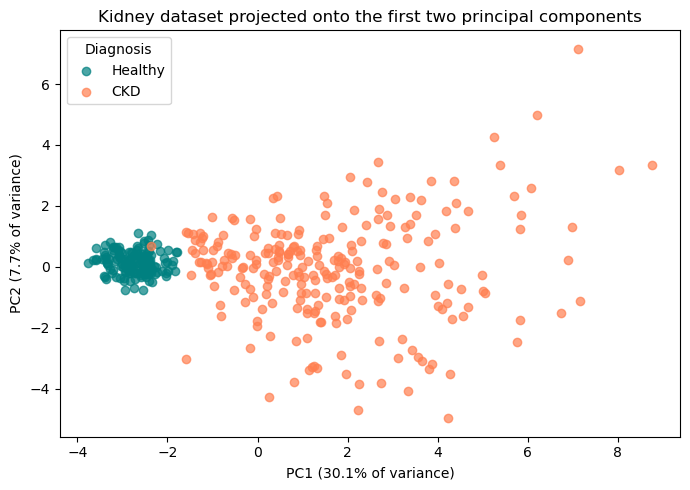

In [65]:
fig, ax = plt.subplots(figsize=(7, 5))

for value, label, color in groups:
    mask = np.asarray(y == value)
    ax.scatter(
        scores[mask, 0],
        scores[mask, 1],
        color=color,
        label=label,
        alpha=0.7,
    )

ax.set_xlabel(f"PC1 ({explained_ratio[0]:.1%} of variance)")
ax.set_ylabel(f"PC2 ({explained_ratio[1]:.1%} of variance)")
ax.set_title("Kidney dataset projected onto the first two principal components")
ax.legend(title="Diagnosis")

plt.tight_layout()
plt.show()

The first two principal components summarize approximately 37.8% of variance. In this projection, healthy and CKD patients form two very distinct groups, making it easier to cluster them visually.

**What is the smallest number of dimensions that contains at least 90% of the information of the data?**

In [67]:
variance_summary = pd.DataFrame({
    "Component": np.arange(1, len(explained_ratio) + 1),
    "Explained variance (%)": explained_ratio * 100,
    "Cumulative variance (%)": np.cumsum(explained_ratio) * 100,
})

display(variance_summary.round(2))

,Component,Explained variance (%),Cumulative variance (%)
0,1,30.07,30.07
1,2,7.70,37.78
2,3,6.72,44.50
3,4,5.32,49.83
4,5,5.06,54.89
5,6,4.50,59.39
6,7,4.21,63.60
7,8,4.17,67.77
8,9,3.69,71.46
9,10,3.32,74.79


As we see in the table, with 17 dimensions we'd maintain 91.74% of the original variance, which corresponds to 7 fewer dimensions, or a 29.17% reduction in dimensionality.

**After projecting the data onto the lower dimensional space, you can approximately recover the data by projecting them back onto the original high dimensional space. Compute this approximation using 10 components. Which is the reconstruction error?**

In [68]:
scores_10, components_10, _, pca_mean = pca_manual(X_stand, n_components=10)

X_reconstructed = scores_10 @ components_10.T + pca_mean

mse = np.mean((np.asarray(X_stand) - X_reconstructed) ** 2)
print(f"Reconstruction MSE: {mse:.6f}")

Reconstruction MSE: 0.251509


An MSE of 0 would mean perfect reconstruction. The value reflects the variance lost by retaining only 10 components, which preserve approximately 75% of the total variance.

## 1.3. Application to face image data

**Load the dataset faces.mat and visualize the first 100 faces**

In [83]:
data_faces = loadmat("../data/faces.mat")

X_faces = data_faces["X"]

In [86]:
X_faces

array([[ -37.86631387,  -45.86631387,  -53.86631387, ..., -110.86631387,
        -111.86631387,  -99.86631387],
       [   8.13368613,   -0.86631387,   -8.86631387, ...,  -34.86631387,
          -8.86631387,    0.13368613],
       [ -32.86631387,  -34.86631387,  -36.86631387, ..., -110.86631387,
        -111.86631387, -111.86631387],
       ...,
       [ -46.86631387,  -24.86631387,   -8.86631387, ...,   90.13368613,
          80.13368613,   59.13368613],
       [  19.13368613,   16.13368613,   14.13368613, ...,  -38.86631387,
         -41.86631387,  -46.86631387],
       [-108.86631387, -106.86631387, -102.86631387, ...,   17.13368613,
          17.13368613,   18.13368613]])

In [84]:
def show_image(pixels, ax):
	image = np.asarray(pixels).reshape(32, 32, order="F")
	ax.imshow(image, cmap="gray")
	ax.axis("off")

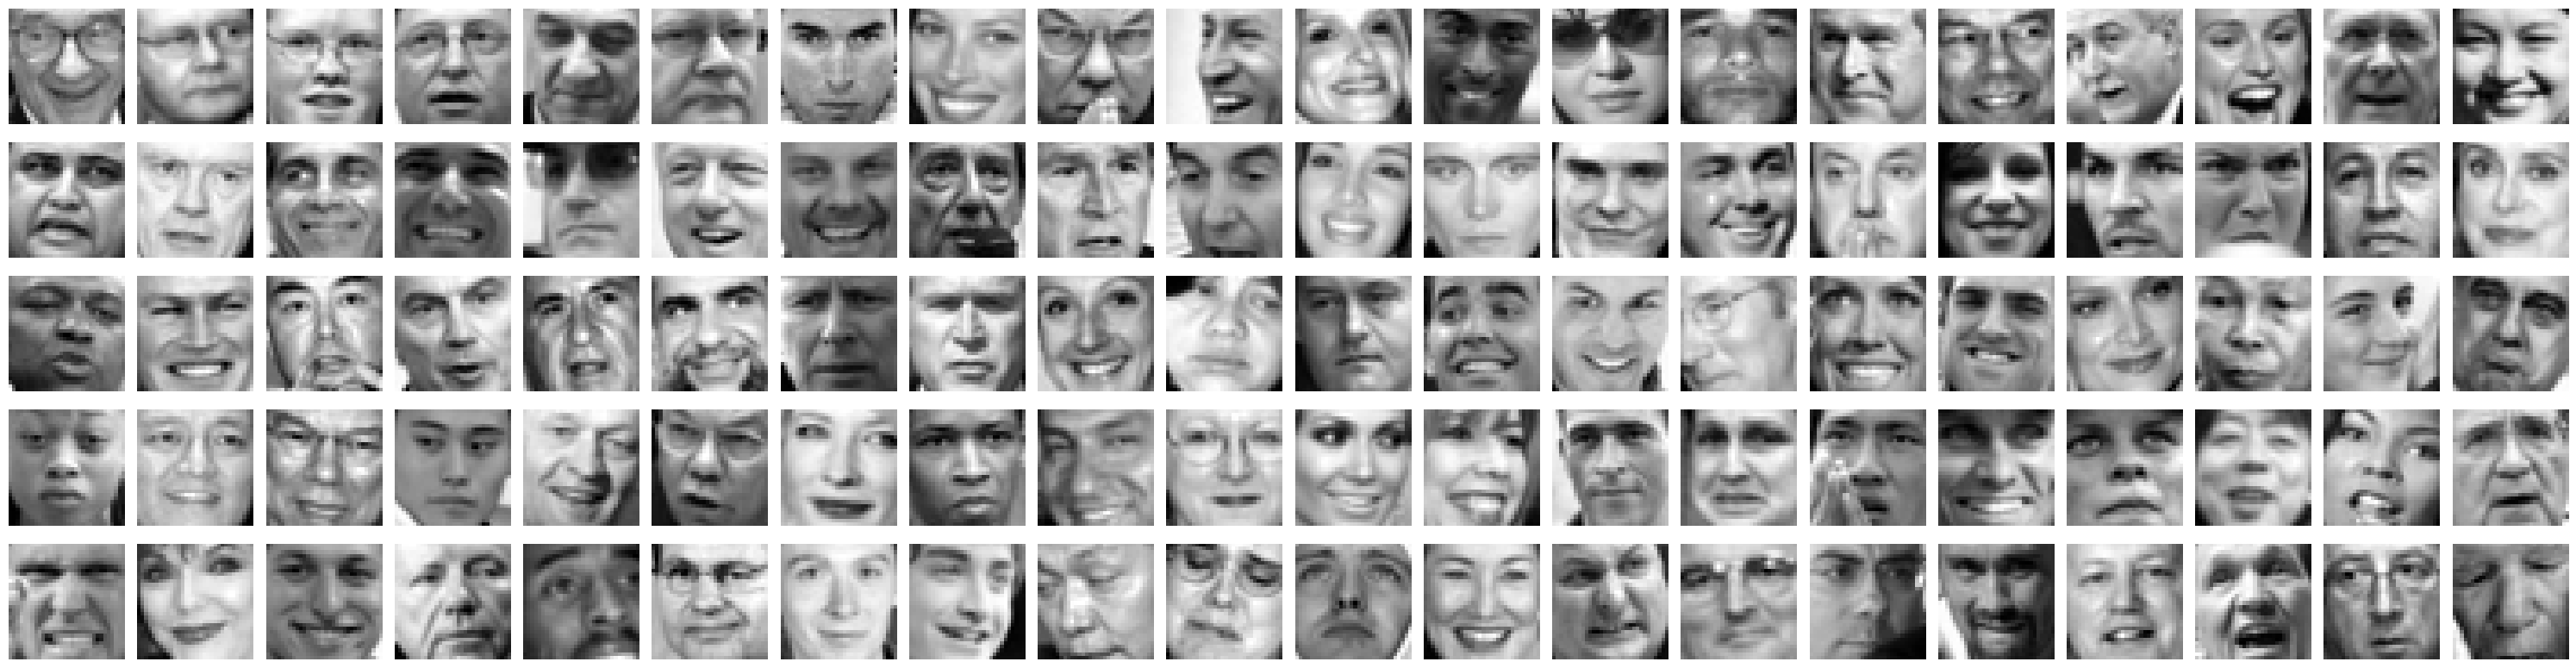

In [85]:
fig, axes = plt.subplots(5, 20, figsize=(30, 8))

images = np.asarray(X_faces)

for i, ax in enumerate(axes.flatten()):
	show_image(images[i], ax)

plt.tight_layout()
plt.show()

**Normalize the dataset to have zero mean and run PCA to obtain the principal components. Justify whether standardization (i.e. rescaling to have unit variance) is needed.**

In [81]:
mean_faces = X_faces.mean(axis=0)
X_faces_centered = X_faces - mean_faces

In [78]:
scores_faces, components_faces, explained_ratio_faces, pca_mean_faces = pca_manual(X_faces_centered)

In this case unit variance is not necessary because all features represent grayscale intensities on the same scale.

**Note that each principal component is of length 1024. You can visualize these principal components by reshaping each of them into a 32 × 32 matrix that corresponds to the pixels in the original dataset. Visualize the first 36 principal components that describe the largest variations. Observe how they capture more and more details.**

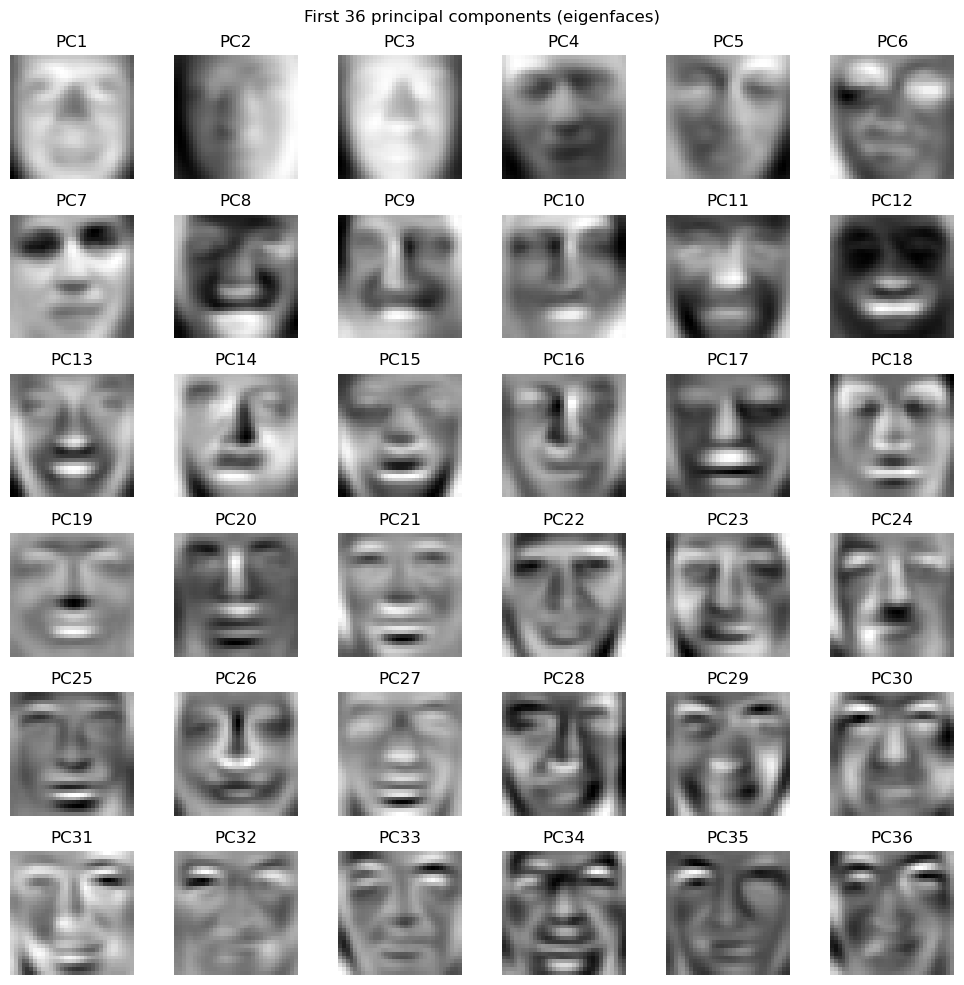

In [ ]:
fig, axes = plt.subplots(6, 6, figsize=(10, 10))

for i, ax in enumerate(axes.flatten()):
    show_image(components_faces[:, i], ax)
    ax.set_title(f"PC{i + 1}")

plt.tight_layout()
plt.show()

**Project the face dataset onto the first 100 principal components. Now, each face image is described by a vector of length 100.**

In [89]:
scores_faces_100 = scores_faces[:, :100]

print(scores_faces_100.shape)

(5000, 100)


**Recover the data using the projected dataset. Visualize the first 100 reconstructed faces and compare it to the original ones.**

In [93]:
X_faces_reconstructed = scores_faces_100 @ components_faces[:, :100].T + pca_mean_faces + mean_faces

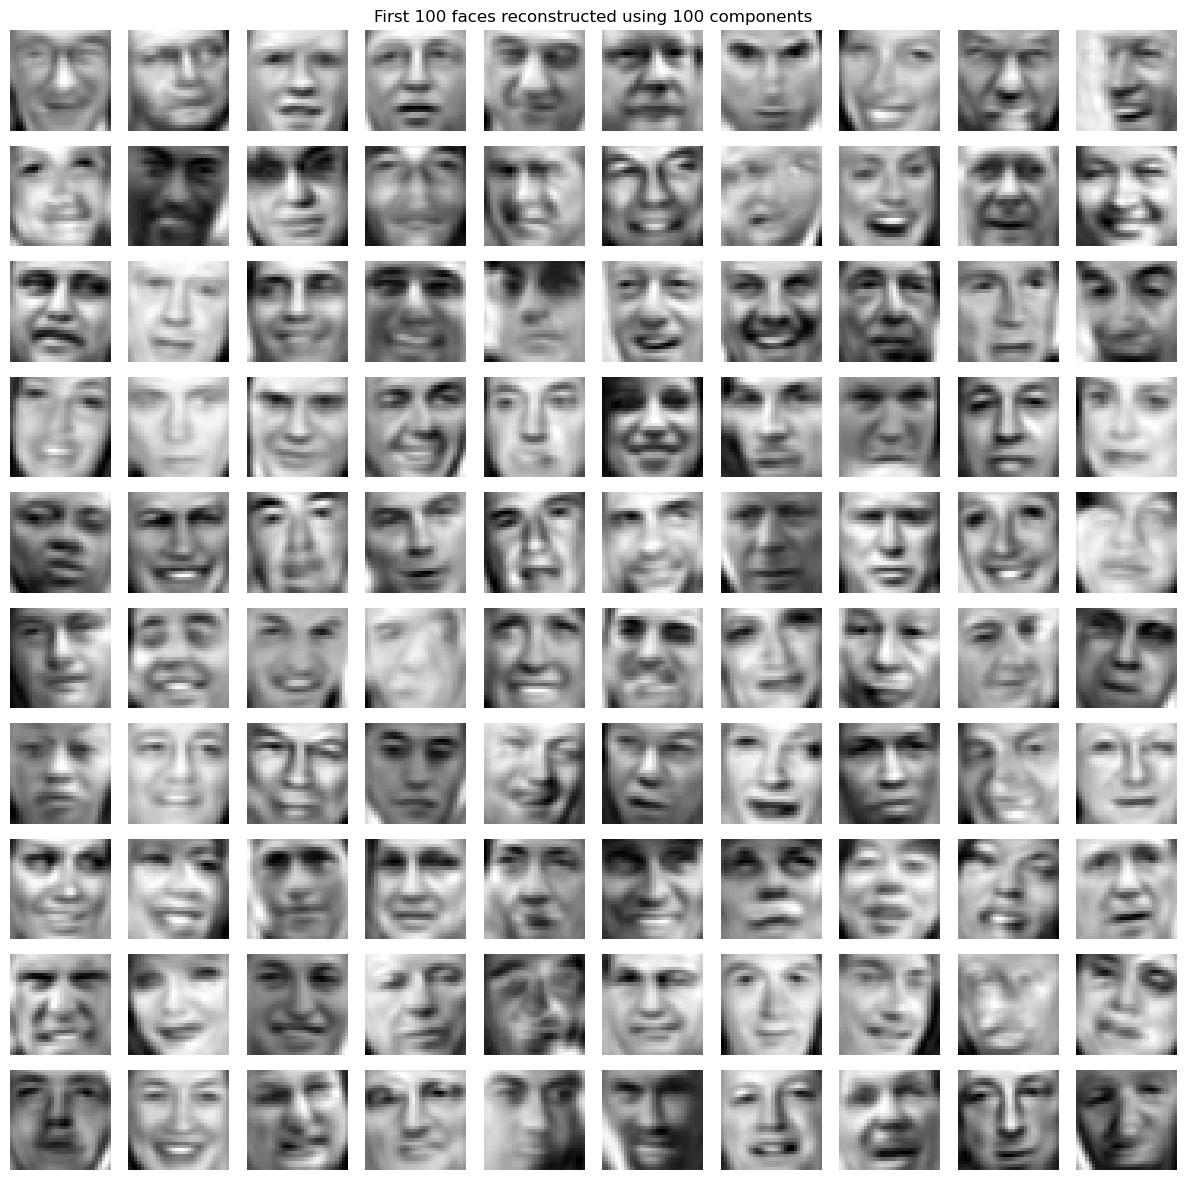

In [94]:
fig, axes = plt.subplots(10, 10, figsize=(12, 12))

for i, ax in enumerate(axes.flat):
    show_image(X_faces_reconstructed[i], ax)

fig.suptitle("First 100 faces reconstructed using 100 components")
plt.tight_layout()
plt.show()

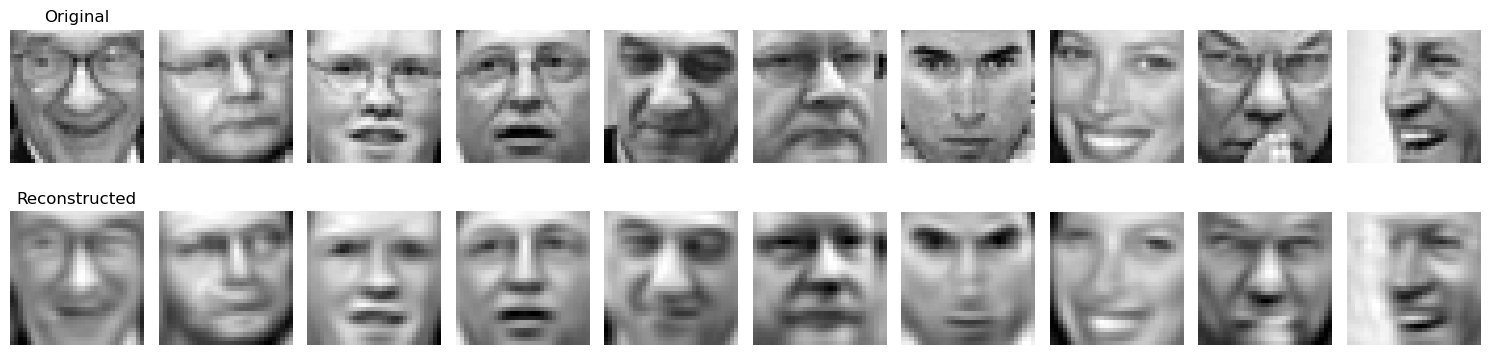

In [95]:
fig, axes = plt.subplots(2, 10, figsize=(15, 4))

for i in range(10):
    show_image(X_faces[i], axes[0, i])
    show_image(X_faces_reconstructed[i], axes[1, i])

axes[0, 0].set_title("Original")
axes[1, 0].set_title("Reconstructed")

plt.tight_layout()
plt.show()

Using only 100 principal components instead of the original 1024 pixel values, we can see that the reconstructed faces preserve the main facial structure and remain recognizable. We can interpret this as reducing image complexity, with an effect similar to blurring: the main facial structure is preserved but some details are lost.

# 2. Clustering: application to cardiac data

## 2.1. Extracting features

**Load the data in cardiacShapes.mat, which consists of the data from 106 acquisitions (71 volunteers and 35 cases with hypertrophic cardiomyopathy).**